<a href="https://colab.research.google.com/github/zhiyuguo-innis/MSSP607/blob/main/WeeklyModules/Week04/Participation_Activity_Week4_Solutions.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

MODIFIED FOR COURSE FROM SOURCE:
Moline, S. (2019). Hands-On Data Analysis with Pandas, Chapter 2. Packt Publishing.

# Solutions
There will be many ways to solve these exercises which weren't covered in this chapter; however, the solutions below use only what has been introduced in chapter 2.

## About the Data
In this notebook, we will be working with Earthquake data from September 18, 2018 - October 13, 2018 (obtained from the US Geological Survey (USGS) using the [USGS API](https://earthquake.usgs.gov/fdsnws/event/1/))

## Setup

We discussed connecting our Google Drives with the Colab Notebooks and uploading data files in class.   I used the code supplied by Google to connect my Google Drive and upload data, and I upload a data file every time I run the import code.


Also, remember that in the first week of class, we ran a file to import several methods and functions to complete basic data analysis.

I copied a connection and the file import code into a python file and imported it to my Google Drive.  I can now run this file whenever I need to connect my drive and get a data file into my Google Drive.


In [ ]:
from google.colab import drive  #I put this code into a Python file called Google_Connection and copied it to my Google Drive
drive.mount('/content/drive')

In [ ]:
from google.colab import files  #I put this into a Python file called Google_connection and copied it to my Google Drivce

uploaded = files.upload()

for fn in uploaded.keys():
  print('User uploaded file "{name}" with length {length} bytes'.format(
      name=fn, length=len(uploaded[fn])))

In [ ]:
# I ran the Google_Connection Python file to connect Google Drive and upload data
# as an alternative to retying the connection code above.

runfile('/content/drive/MyDrive/MSSP607/CodeSamples/Google_Connection.py') # I can run the Google_Connection Python file to connect Google Drive and upload data

You may recall from the previous demonstration that when I upload files using the Google Colab code above, they are stored in my drive accordingly.  See the drive content files below.

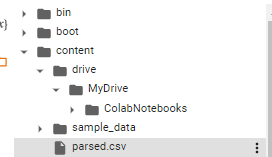

In [ ]:
import pandas as pd  #Import the Pandas library with its full capabilities.

#Make sure you type to correct path to the file you need.
#I eliminated spaces as a naming convention; this causes less confusion for myself and Python when looking for the path.

df = pd.read_csv('/content/parsed.csv') #read the csv file into a Pandas dataframe
df.columns #display the columns of the dataframe

#How to filter the Dataframe#

The first step is to filter the df dataframe to select the appropirate data for analysis.  In this case, review the panda documentation on how to filter dataframes. See: https://pandas.pydata.org/docs/getting_started/intro_tutorials/03_subset_data.html

Filtering a Pandas DataFrame involves selecting specific rows or columns based on certain conditions or criteria. Pandas provides various methods and techniques to filter data in a DataFrame. Here are some common ways to filter a Pandas DataFrame:

1. Boolean Indexing:

filtered_df = df[df['column_name'] > 5]

2. Multiple conditions

filtered_df = df[(df['column1'] > 5) & (df['column2'] < 10)]

3. isin() Method

values_to_filter = [1, 2, 3]
filtered_df = df[df['column_name'].isin(values_to_filter)]

4. String Filtering:

filtered_df = df[df['column_name'].str.startswith('abc')]

5. Query Method:

filtered_df = df.query('column1 > 5 and column2 < 10')

6. loc and iloc

filtered_df = df.loc[df['column_name'] > 5, ['column1', 'column2']]

7. Custom Functions

def my_filter_function(row):
    # Custom filtering logic here
    return row['column1'] > 5 and row['column2'] < 10

filtered_df = df[df.apply(my_filter_function, axis=1)]




In [ ]:
results = df[(df.parsed_place.str.endswith('Japan')) & (df.magType == 'mb')]
results

In [ ]:
#Using tab completion we can get the column names
results.columns

In [ ]:
results[['parsed_place', 'mag']]

In [ ]:
#One solution is to import Numpy and use its percentile method to caluclate the 95%
#Remember, we filtered the original dataframe to get the 'results' dataframe, then sent the 'mag' sequence to the Numpy method
import numpy as np
percentile_95 = np.percentile(results.mag,95) #Select the 'mag' series.
print('The 95th percentile of earthquakes in Japan is',percentile_95)

## Exercise 1

In [ ]:
#You may recall that in the first week of class, we reviewed the Introduction_to_data_analysis Notebook.
#In that Notebook, there is an example of calculating quintiles.
#For this example, you can reference https://docs.python.org/3/library/statistics.html?highlight=quartiles#statistics.quantiles
#We need to filter the original dataframe to select the instances that meet the criteria

#Alternatively, we can use Pandas' methods to calcualte the 95%, but we neet to fileter the original dataframe.
#Here we work from inside the '()' outward to build an object where we can use the quantile method on the mag series(column).

print('The 95th percentile of earthquakes in Japan is',df[(df.parsed_place.str.endswith('Japan')) & (df.magType == 'mb')].mag.quantile(0.95))

## Exercise 2

In [ ]:
df[df.parsed_place.str.endswith('Indonesia')].describe()

In [ ]:
#
#Using the f-strings as a way to format strings:

f"""{df[df.parsed_place.str.endswith('Indonesia')].tsunami.value_counts(normalize=True).loc[1,]:.2%}"""


## Exercise 3

In [ ]:
#Get summary statistics for earthquakes in Nevada
df[df.parsed_place.str.endswith('Nevada')].describe()

## Exercise 4
Note we need to use `^Mexico` to get Mexico, but not New Mexico.

The caret symbol '^' is a regular Python expression used in statements. It serves as an anchor to specify that the string pattern should match at the start of a line or string.  In this case, we want all countries and only the country Mexico.  We append the series "ring_of_fire to the end of the dataframe when we reference the series. See https://docs.python.org/3/library/re.html?highlight=string%20pattern%20matching


In [ ]:
df['ring_of_fire'] = ''
df.columns

In [ ]:
df['ring_of_fire'] = df.parsed_place.str.contains(r'|'.join([
    'Bolivia', 'Chile', 'Ecuador', 'Peru', 'Costa Rica',
    'Guatemala', '^Mexico', 'Japan', 'Philippines', 'Indonesia',
    'New Zealand', 'Antarctic', 'Canada', 'Fiji',
    'Alaska', 'Washington', 'California', 'Russia',
    'Taiwan', 'Tonga', 'Kermadec Islands'
]))
df[['ring_of_fire', 'parsed_place']]

In [ ]:
df[['ring_of_fire', 'parsed_place']]

## Exercise 5

Question: Calculate the number of earthquakes in the Ring of Fire locations and the number outside of them

In [ ]:
#Calculate the total number of events in the dataframe
df.type.value_counts()

In [ ]:
#Filter the dataframe for earthquakes on the ring of fire and outside of the ring.
filtered_df = df[(df['ring_of_fire'] == True) & (df['type'] == 'earthquake')]
total_inside = df[(df['ring_of_fire'] == True) & (df['type'] == 'earthquake')].type.count()
total_outside = df[(df['ring_of_fire'] == False) & (df['type'] == 'earthquake')].type.count()
print('The total number of earthquakes in the Ring of Fire is: ', total_inside)
print('The total number of earthquakes outside the Ring of Fire is: ', total_outside)


In [ ]:
#"An earthquake is caused by a sudden slip on a fault. The tectonic plates are always slowly moving,
#but they get stuck at their edges due to friction. When the stress on the edge overcomes the friction,
#there is an earthquake that releases energy in waves that travel through the earth's crust and cause
#the shaking that we feel."  - https://www.usgs.gov/faqs/what-earthquake-and-what-causes-them-happen

In [ ]:
#Per the dictionary, an earthquake is a "shaking or trembling of the earth that is volcanic or tectonic in origin" - https://www.merriam-webster.com/dictionary/earthquake
#Other definitions, An earthquake (also known as a quake, tremor, big shake or temblor) is the shaking of the
#surface of the Earth resulting from a sudden release of energy in the Earth's lithosphere that creates seismic waves."
#https://en.wikipedia.org/wiki/Earthquake#:~:text=An%20earthquake%20%28also%20known%20as%20a%20quake%2C%20tremor,the%20Earth%20%27s%20lithosphere%20that%20creates%20seismic%20waves.

#Calulating the number of events that generate seismic activity.
#Defining any movement that records seismic activity
df['ring_of_fire'].value_counts()

## Exercise 6

In [ ]:
#.loc and .iloc are two important methods used for
#selecting data from a Pandas DataFrame or Series in Python.
#They allow you to access specific rows and columns of your data.

df.loc[df.ring_of_fire, 'tsunami'].sum()